# Ek C — Python Kod Örnekleri ve Veri Hazırlama
### Gömülü modüllerin kendi verinizle kullanımı

*İK Profesyonelleri için Metrik El Kitabı*

Rehber sayfalarının her birinde, hesaplayıcının arkasında çalışan bir **Python modülü** gömülüdür (sayfadaki “Python” sekmesi). Bu defter, bu modüllerin tarayıcının dışında, **kendi İK verinizle** nasıl kullanılacağını adım adım gösterir:

1. Modülleri içe aktarma
2. Ham İK tablolarını okuma ve **veri hazırlama** (temizleme, kalite kontrolü)
3. Tablolardan modüllerin istediği **girdileri üretme** (pandas ile)
4. Modüllerin `hesapla()` işlevi ve fonksiyonlarıyla metrik hesaplama
5. Sonuçları tek bir özet tabloda toplama ve dışa aktarma
6. Kendi verinize uyarlama (sütun eşleme, kontrol listesi)

> **Önemli:** Bu defterdeki veriler **yapay (sentetik) olarak üretilmiştir**. “Örnek Anonim Sanayi A.Ş.” adlı kurgusal bir kurumun 2025 yılını temsil eder; hiçbir gerçek kişi ya da kuruma ait değildir. Sonuçlar yalnızca yöntemi göstermek içindir, yorum ya da kıyas amacıyla kullanılmamalıdır.

**Paket içeriği**

| Klasör / dosya | Açıklama |
|---|---|
| `Ek_C_Python_Kod_Ornekleri.ipynb` | Bu defter |
| `modules/` | 25 rehberden çıkarılmış Python modülleri (`isoXXXXX_metrikler.py`) |
| `veri/` | Yapay CSV dosyaları (çalışan, işe alım, eğitim, anket, İSG, yedekleme, finans) |
| `veri/veri_sozlugu.csv` | Her dosyadaki sütunların açıklaması |

**Gereksinimler:** Python 3.9+ ve `pandas`, `numpy` (grafikler için isteğe bağlı `matplotlib`). Modüllerin kendisi yalnızca standart kütüphaneyi kullanır.

## C.1 Kurulum: modülleri içe aktarma

In [1]:
import sys, pathlib, importlib
import numpy as np
import pandas as pd

KOK = pathlib.Path.cwd()                  # defteri paket klasöründe açın
sys.path.insert(0, str(KOK / "modules"))  # modüllerin bulunduğu klasör
VERI = KOK / "veri"

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 30

# Modülleri adlarıyla içe aktarıyoruz. Her modülün ortak bir arayüzü vardır:
#   METRIK_LISTESI : desteklenen metrik kimlikleri
#   hesapla(kimlik, **girdiler) : sonuç sözlüğü döndürür
#   ayrıca her metrik için ayrı fonksiyon (ör. aylik_devir, fte, kapsama_orani ...)
def modul(ad):
    return importlib.import_module(ad)

iso30435 = modul("iso30435_metrikler")   # İşgücü veri kalitesi
iso30425 = modul("iso30425_metrikler")   # İşgücü bulunabilirliği (FTE, devamsızlık)
iso30421 = modul("iso30421_metrikler")   # Devir ve elde tutma
iso30430 = modul("iso30430_metrikler")   # İşe alım metrikleri
iso30407 = modul("iso30407_metrikler")   # İşe alım başına maliyet
iso30433 = modul("iso30433_metrikler")   # Yedekleme planlaması
iso30422 = modul("iso30422_metrikler")   # Öğrenme ve gelişim
iso30437 = modul("iso30437_metrikler")   # Öğrenme ve gelişim (etkililik)
iso24179 = modul("iso24179_metrikler")   # İş sağlığı ve güvenliği
iso23326 = modul("iso23326_metrikler")   # Çalışan bağlılığı
iso30427 = modul("iso30427_metrikler")   # Maliyet
iso30432 = modul("iso30432_metrikler")   # Üretkenlik
iso30415 = modul("iso30415_metrikler")   # Çeşitlilik ve kapsayıcılık

print("Hazır. Örnek: ISO/TS 30421 metrikleri ->", iso30421.METRIK_LISTESI[:5], "...")

Hazır. Örnek: ISO/TS 30421 metrikleri -> ['aylik_devir', 'yillik_devir', 'gonullu_gonulsuz', 'kritik_devir', 'uzucu_devir'] ...


**Sonuç sözlüğü.** `hesapla()` her zaman bir sözlük döndürür: `deger` (sayı), `ondalik`, `birim`, `ifade` (formülün yerine konmuş hâli) ve `ayrinti` (etiket–değer çiftleri). Aşağıdaki yardımcı işlevler bu sözlüğü okunur biçimde yazdırır ve sonuçları sonda toplayacağımız bir listeye ekler.

In [2]:
SONUCLAR = []   # (rehber, metrik, değer, birim) satırları; C.13'te tabloya çevrilir

def goster(s, baslik, rehber=None):
    """Sonuç sözlüğünü yazdırır ve özet listeye ekler."""
    o = s.get("ondalik", 2)
    print(f"{baslik}: {s['deger']:,.{o}f} {s.get('birim', '')}")
    print("   formül :", s.get("ifade", ""))
    for e, v in s.get("ayrinti", []):
        print(f"   · {e}: {v:,.2f}" if isinstance(v, (int, float)) else f"   · {e}: {v}")
    if rehber:
        SONUCLAR.append({"Rehber": rehber, "Metrik": baslik,
                         "Değer": round(s["deger"], o), "Birim": s.get("birim", "")})
    return s

## C.2 Veriyi okuma ve hazırlama

Gerçek İK verisi nadiren “hazır”dır: yinelenen kayıtlar, boş alanlar, mantıksız tarihler… Bu bölümde yapay verideki **bilinçli olarak eklenmiş** sorunları bulup düzeltiyoruz. İlke şudur: **önce kontrol et, sonra düzelt, yaptığın her düzeltmeyi kaydet.**

In [3]:
cal = pd.read_csv(VERI / "calisanlar.csv",
                  parse_dates=["ise_baslama_tarihi", "ayrilma_tarihi"])
ise = pd.read_csv(VERI / "isealim_talepleri.csv",
                  parse_dates=["boslugun_bilindigi", "talep_onay_tarihi",
                               "teklif_kabul_tarihi", "baslama_tarihi"])
egt = pd.read_csv(VERI / "egitimler.csv", parse_dates=["tarih"])
anket = pd.read_csv(VERI / "baglilik_anketi.csv")
isg = pd.read_csv(VERI / "isg_aylik.csv")
yed = pd.read_csv(VERI / "yedekleme_havuzu.csv")
fin = pd.read_csv(VERI / "finans_aylik.csv")

for ad, t in [("çalışanlar", cal), ("işe alım", ise), ("eğitim", egt), ("anket", anket),
              ("İSG", isg), ("yedekleme", yed), ("finans", fin)]:
    print(f"{ad:<12} {t.shape[0]:>5} satır × {t.shape[1]:>2} sütun")
cal.head()

çalışanlar     551 satır × 16 sütun
işe alım        95 satır × 15 sütun
eğitim        1466 satır × 11 sütun
anket          392 satır × 12 sütun
İSG             12 satır ×  9 sütun
yedekleme      136 satır ×  6 sütun
finans          12 satır × 11 sütun


,sicil_no,birim,unvan_grubu,kritik_pozisyon,cinsiyet,yas_grubu,istihdam_turu,haftalik_saat,ise_baslama_tarihi,ayrilma_tarihi,ayrilma_turu,uzucu_ayrilma,aylik_brut_ucret,performans_puani,yetkinlik_puani,yonetici_sicil
0,E0001,İnsan Kaynakları,Uzman,0,E,30-39,Tam zamanlı,45.00,2018-03-31,NaT,NaN,0,69100,2.70,2.95,E0003
1,E0002,Ar-Ge,Uzman,0,E,50+,Tam zamanlı,45.00,2021-01-06,NaT,NaN,0,69400,3.10,3.26,E0435
2,E0003,Lojistik,Yönetici,1,K,30-39,Tam zamanlı,45.00,2022-07-05,NaT,NaN,0,92800,4.00,2.71,E0503
3,E0004,Üretim,Operatör,0,K,30-39,Tam zamanlı,45.00,2021-11-15,NaT,NaN,0,36200,3.30,4.10,E0003
4,E0005,Üretim,Operatör,0,E,30-39,Tam zamanlı,45.00,2021-03-02,NaT,NaN,0,37500,3.50,3.40,E0168


**Adım 1 — Kalite kontrolü (düzeltmeden önce yalnızca ölç):**

In [4]:
YIL = 2025
YIL_BASI, YIL_SONU = pd.Timestamp(YIL, 1, 1), pd.Timestamp(YIL, 12, 31)

kontrol = {
    "Yinelenen sicil numarası":        int(cal.sicil_no.duplicated().sum()),
    "Eksik cinsiyet":                  int(cal.cinsiyet.isna().sum()),
    "Eksik performans puanı":          int(cal.performans_puani.isna().sum()),
    "Ayrılma tarihi < başlama tarihi": int((cal.ayrilma_tarihi < cal.ise_baslama_tarihi).sum()),
    "Ayrılma türü eksik (tarih var)":  int((cal.ayrilma_tarihi.notna() & cal.ayrilma_turu.isna()).sum()),
}
pd.Series(kontrol, name="Sorunlu kayıt")

Yinelenen sicil numarası            3
Eksik cinsiyet                      6
Eksik performans puanı             14
Ayrılma tarihi < başlama tarihi     2
Ayrılma türü eksik (tarih var)      0
Name: Sorunlu kayıt, dtype: int64

**Adım 2 — Düzeltme ve kayıt altına alma.** Yinelenenleri atıyoruz; mantıksız tarihli kayıtları ise **sessizce düzeltmek yerine** ayrı bir tabloya alıp analizden çıkarıyoruz (gerçek hayatta kaynağa dönüp doğru değeri bulun).

In [5]:
n0 = len(cal)
cal = cal.drop_duplicates("sicil_no", keep="first").copy()
print("Yinelenen kayıt atıldı:", n0 - len(cal))

tarih_hatali = cal.ayrilma_tarihi < cal.ise_baslama_tarihi
sorunlu = cal[tarih_hatali].copy()           # incelenmek üzere ayrı tutulur
cal = cal[~tarih_hatali].copy()
print("Tarih hatası nedeniyle analiz dışı bırakılan:", len(sorunlu))
print(sorunlu[["sicil_no", "birim", "ise_baslama_tarihi", "ayrilma_tarihi"]].to_string(index=False))

# Türetilmiş alanlar (sonraki bölümlerde kullanılacak)
cal["kidem_ay"] = ((cal.ayrilma_tarihi.fillna(YIL_SONU) - cal.ise_baslama_tarihi).dt.days / 30.4375)
print("\nHazır çalışan tablosu:", cal.shape)

Yinelenen kayıt atıldı: 3
Tarih hatası nedeniyle analiz dışı bırakılan: 2
sicil_no              birim ise_baslama_tarihi ayrilma_tarihi
   E0173 Satış ve Pazarlama         2020-01-29     2020-01-14
   E0216             Üretim         2022-05-16     2022-05-01

Hazır çalışan tablosu: (546, 17)


**Adım 3 — Zaman noktasındaki mevcut sayısı.** Devir, FTE ve kıdem hesaplarının neredeyse hepsi “belirli bir günde kaç kişi çalışıyordu?” sorusuna dayanır. Bunu tek bir işlevde toplamak hataları azaltır.

In [6]:
def mevcut(tarih, tablo=None):
    """Verilen günün sonunda işte olan çalışanlar (başlamış ve henüz ayrılmamış)."""
    t = cal if tablo is None else tablo
    tarih = pd.Timestamp(tarih)
    return t[(t.ise_baslama_tarihi <= tarih) &
             (t.ayrilma_tarihi.isna() | (t.ayrilma_tarihi > tarih))]

onceki_gun = YIL_BASI - pd.Timedelta(days=1)
print("Yıl başı mevcut :", len(mevcut(onceki_gun)))
print("Yıl sonu mevcut :", len(mevcut(YIL_SONU)))

Yıl başı mevcut : 468
Yıl sonu mevcut : 478


## C.3 Veri kalitesi skor kartı — ISO 30435

Metrik hesaplamadan **önce** verinin ne kadar güvenilir olduğunu ölçün. Modülün `skor_karti` metriği beş boyutun en zayıfını (en zayıf halka) bulur.

In [7]:
ham = pd.read_csv(VERI / "calisanlar.csv")        # temizlenmemiş hâl
zorunlu = ["birim", "cinsiyet", "performans_puani", "ise_baslama_tarihi"]

dolu = int(ham[zorunlu].notna().sum().sum())
beklenen = len(ham) * len(zorunlu)
tamlik = iso30435.hesapla("tamlik", dolu=dolu, beklenen=beklenen, esik=98)

tutarsiz = int(kontrol["Yinelenen sicil numarası"] + kontrol["Ayrılma tarihi < başlama tarihi"])
tutarlilik = iso30435.hesapla("tutarlilik", karsilastirilan=len(ham), tutarsiz=tutarsiz)

# Doğruluk: 100 kayıtlık rastgele örneği elle doğruladığınızı varsayalım (3 hatalı bulundu)
dogruluk = iso30435.hesapla("dogruluk", ornek=100, hatali=3, esik=95)

goster(tamlik, "Zorunlu alan tamlığı", "ISO 30435")
goster(tutarlilik, "Tutarlılık", "ISO 30435")
goster(dogruluk, "Doğruluk (örneklem)", "ISO 30435")

skor = iso30435.hesapla("skor_karti", dogruluk=dogruluk["deger"], guncellik=96.0,   # güncellik ve uygunluk burada varsayımdır; kendi sistem kayıtlarınızdan hesaplayın
                        
                        tamlik=tamlik["deger"], tutarlilik=tutarlilik["deger"], uygunluk=100.0)
goster(skor, "Veri kalitesi — en zayıf halka", "ISO 30435")

Zorunlu alan tamlığı: 99.1 % tamlık
   formül : (2184 ÷ 2204) × 100
   · Eksik alan: 20.00
   · Eksik payı (%): 0.90
   · Gerekli düzey karşılandı mı: Evet
Tutarlılık: 99.1 % tutarlı
   formül : (1 − 5 ÷ 551) × 100
   · Tutarlı kayıt: 546.00
   · Tutarsız kayıt: 5.00
   · Bin kayıtta tutarsızlık: 9.00
Doğruluk (örneklem): 97.0 % doğruluk
   formül : (1 − 3 ÷ 100) × 100
   · Hata oranı (%): 3.00
   · Gerekli düzeyden fark (puan): 2.00
   · Gerekli düzey karşılandı mı: Evet
Veri kalitesi — en zayıf halka: 96.0 % (en zayıf boyut)
   formül : min(97, 96, 99.0925589837, 99.0925589837, 100)
   · En zayıf boyut: Güncellik
   · Boyutların ortalaması (%): 98.20
   · En güçlü ile en zayıf arasındaki fark (puan): 4.00


{'deger': 96.0,
 'ondalik': 1,
 'birim': '% (en zayıf boyut)',
 'ifade': 'min(97, 96, 99.0925589837, 99.0925589837, 100)',
 'ayrinti': [['En zayıf boyut', 'Güncellik'],
  ['Boyutların ortalaması (%)', 98.2],
  ['En güçlü ile en zayıf arasındaki fark (puan)', 4.0]]}

## C.4 Kapasite: çalışan sayısı ve FTE — ISO/TS 30425

`fte` metriği, tam zamanlı çalışan sayısına yarı zamanlıların haftalık saat toplamının tam zamanlı haftalık saate oranını ekler (FTE = A + B ÷ C).

In [8]:
yil_sonu = mevcut(YIL_SONU)
tam = yil_sonu[yil_sonu.istihdam_turu != "Yarı zamanlı"]
yari = yil_sonu[yil_sonu.istihdam_turu == "Yarı zamanlı"]

fte = iso30425.hesapla("fte",
                       tam_zamanli=len(tam),                 # A: tam zamanlı kişi
                       yari_saat=float(yari.haftalik_saat.sum()),   # B: yarı zamanlıların haftalık saati
                       haftalik_saat=45.0)                   # C: tam zamanlı haftalık saat
goster(fte, "Yıl sonu FTE", "ISO/TS 30425")

# Koşullu işgücü payı (geçici çalışanlar / toplam)
kosullu = (yil_sonu.istihdam_turu == "Geçici").sum()
print("\nGeçici çalışan payı: %.1f %%" % (100 * kosullu / len(yil_sonu)))

Yıl sonu FTE: 463.5 FTE
   formül : 449 + (652.5 ÷ 45)
   · Yarı zamanlıların FTE karşılığı: 14.50
   · Yarı zamanlı FTE payı (%): 3.10
   · Tam zamanlı çalışanın payı (%): 96.90

Geçici çalışan payı: 4.4 %


## C.5 Devir ve elde tutma — ISO/TS 30421

Önce 12 aylık **devir tablosu** hazırlıyoruz: her ay için ay başı mevcut, ay sonu mevcut, gönüllü ve gönülsüz ayrılan sayıları. Modülün `DevirTablosu` sınıfı tam bu yapıyı bekler.

In [9]:
aylar = pd.period_range(f"{YIL}-01", f"{YIL}-12", freq="M")
satirlar = []
for p in aylar:
    bas_gun = p.start_time - pd.Timedelta(days=1)
    son_gun = p.end_time.normalize()
    ayr = cal[(cal.ayrilma_tarihi > bas_gun) & (cal.ayrilma_tarihi <= son_gun)]
    satirlar.append({"ay": str(p),
                     "basi": len(mevcut(bas_gun)), "sonu": len(mevcut(son_gun)),
                     "gonullu": int((ayr.ayrilma_turu == "Gönüllü").sum()),
                     "gonulsuz": int((ayr.ayrilma_turu == "Gönülsüz").sum())})
aylik = pd.DataFrame(satirlar)
aylik["ayrilan"] = aylik.gonullu + aylik.gonulsuz
aylik["devir_%"] = aylik.apply(lambda r: iso30421.aylik_devir(r.ayrilan, r.basi, r.sonu), axis=1)
aylik

,ay,basi,sonu,gonullu,gonulsuz,ayrilan,devir_%
0,2025-01,468,474,1,1,2,0.42
1,2025-02,474,473,4,0,4,0.84
2,2025-03,473,479,2,2,4,0.84
3,2025-04,479,483,4,0,4,0.83
4,2025-05,483,483,2,3,5,1.04
5,2025-06,483,487,3,1,4,0.82
6,2025-07,487,484,4,3,7,1.44
7,2025-08,484,485,4,2,6,1.24
8,2025-09,485,485,5,2,7,1.44
9,2025-10,485,487,6,1,7,1.44


In [10]:
tablo = iso30421.DevirTablosu()
for r in aylik.itertuples():
    tablo.ekle(r.ay, r.gonullu, r.gonulsuz, r.basi, r.sonu)

ozet = tablo.ozet()
print({k: v for k, v in ozet.items()})

yillik = iso30421.hesapla("yillik_devir", oran_toplami=tablo.yillik_oran,
                          toplam_ayrilan=tablo.toplam_ayrilan,
                          ortalama_mevcut=tablo.ortalama_mevcut)
goster(yillik, "Yıllık devir oranı", "ISO/TS 30421")

gonullu = iso30421.hesapla("gonullu_gonulsuz", gonullu=int(aylik.gonullu.sum()),
                           gonulsuz=int(aylik.gonulsuz.sum()), ortalama_mevcut=tablo.ortalama_mevcut)
goster(gonullu, "Gönüllü devir", "ISO/TS 30421")

{'yillik_devir': 14.09, 'kaba_yillik_devir': 14.12, 'gonullu_devir': 9.95, 'gonullu_pay': 70.6, 'basit_elde_tutma': 85.91, 'toplam_ayrilan': 68, 'ortalama_mevcut': 481.6}
Yıllık devir oranı: 14.09 % / yıl
   formül : Σ aylık oranlar = 14.0861
   · Kaba yöntem (toplam ayrılan ÷ ortalama işgücü): 14.12
   · İki yöntem arasındaki fark (puan): -0.03
   · Elde tutma karşılığı (%): 85.91
Gönüllü devir: 9.97 % gönüllü devir
   formül : (48 ÷ 481.583) × 100
   · Gönülsüz devir (%): 4.15
   · Toplam devir (%): 14.12
   · Gönüllünün toplam ayrılmadaki payı (%): 70.60


{'deger': 9.967122339505105,
 'ondalik': 2,
 'birim': '% gönüllü devir',
 'ifade': '(48 ÷ 481.583) × 100',
 'ayrinti': [['Gönülsüz devir (%)', 4.15],
  ['Toplam devir (%)', 14.12],
  ['Gönüllünün toplam ayrılmadaki payı (%)', 70.6]]}

**Kritik pozisyon devri** ve **üzücü (regrettable) devir**: ayrılanları kritik/üzücü olarak işaretleyen sütunlarımız olduğu için doğrudan filtreleyebiliriz.

In [11]:
krit = cal[cal.kritik_pozisyon == 1]
krit_ayr = int(krit.ayrilma_tarihi.notna().sum())
# Not: modül birimi “% / ay” diye etiketler; burada ay yerine tüm yılı verdiğimiz için sonuç yıllıktır.
kd = iso30421.hesapla("kritik_devir", kritik_ayrilan=krit_ayr,
                      kritik_basi=len(mevcut(onceki_gun, krit)), kritik_sonu=len(mevcut(YIL_SONU, krit)),
                      toplam_isgucu=len(yil_sonu))
goster(kd, "Kritik pozisyon devri (yıllık)", "ISO/TS 30421")

uz = iso30421.hesapla("uzucu_devir", uzucu=int(cal.uzucu_ayrilma.sum()),
                      toplam_ayrilan=int(cal.ayrilma_tarihi.notna().sum()),
                      ortalama_mevcut=tablo.ortalama_mevcut)
goster(uz, "Üzücü (regrettable) devir", "ISO/TS 30421")

Kritik pozisyon devri (yıllık): 17.32 % / ay (kritik)
   formül : (20 ÷ 115.5) × 100
   · Kritik kadronun ortalaması: 115.50
   · Aynı kayıp, toplam işgücüne göre (%): 4.18
   · Kritik kadronun işgücü içindeki payı (%): 24.20
Üzücü (regrettable) devir: 4.15 % üzücü devir
   formül : (20 ÷ 481.583) × 100
   · Üzücü ayrılmanın toplam içindeki payı (%): 29.40
   · Üzücü olmayan ayrılma: 48.00


{'deger': 4.15296764146046,
 'ondalik': 2,
 'birim': '% üzücü devir',
 'ifade': '(20 ÷ 481.583) × 100',
 'ayrinti': [['Üzücü ayrılmanın toplam içindeki payı (%)', 29.4],
  ['Üzücü olmayan ayrılma', 48]]}

**Elde tutma ve kıdem:**

In [12]:
bas = len(mevcut(onceki_gun))
et = iso30421.hesapla("basit_elde_tutma", yillik_devir=yillik["deger"], donem_basi=bas)
goster(et, "Basit elde tutma oranı", "ISO/TS 30421")

kidem = iso30421.hesapla("ortalama_kidem", kumulatif_kidem_ay=float(yil_sonu.kidem_ay.sum()),
                         kisi_sayisi=len(yil_sonu))
goster(kidem, "Ortalama kıdem", "ISO/TS 30421")

# İstikrar oranı: 1 yıldan kıdemli çalışanlar / bir yıl önceki mevcut
bir_yil_once = len(mevcut(YIL_SONU - pd.DateOffset(years=1)))
kidemli = int((yil_sonu.kidem_ay >= 12).sum())
ist = iso30421.hesapla("istikrar_orani", bir_yildan_kidemli=kidemli,
                       bir_yil_once_mevcut=bir_yil_once, bugunku_mevcut=len(yil_sonu))
goster(ist, "İstikrar oranı (1+ yıl)", "ISO/TS 30421")

Basit elde tutma oranı: 85.91 %
   formül : 100 − 14.0861
   · Yıllık devir oranı (%): 14.09
   · Yıl sonunda beklenen kalan (kişi): 402.10
   · Yenilenmesi gereken kadro (kişi): 65.90
Ortalama kıdem: 38.3 ay
   formül : 18290.2 ÷ 478
   · Yıl karşılığı: 3.19
   · Yıl ve ay olarak: 3 yıl 2 ay
İstikrar oranı (1+ yıl): 89.3 % istikrar
   formül : (418 ÷ 468) × 100
   · Bir yıl içinde ayrılan (kişi): 50.00
   · Bugünkü mevcutta kıdemsizlerin payı (%): 12.60


{'deger': 89.31623931623932,
 'ondalik': 1,
 'birim': '% istikrar',
 'ifade': '(418 ÷ 468) × 100',
 'ayrinti': [['Bir yıl içinde ayrılan (kişi)', 50],
  ['Bugünkü mevcutta kıdemsizlerin payı (%)', 12.6]]}

## C.6 İşe alım — ISO/TS 30430 ve ISO/TS 30407

In [13]:
dold = ise[ise.durum == "Dolduruldu"].copy()
dold["doldurma_gun"] = (dold.teklif_kabul_tarihi - dold.talep_onay_tarihi).dt.days   # onaydan teklif kabulüne

aqc = iso30430.hesapla("aqc", nitelikli=int(ise.nitelikli_aday.sum()),
                       pozisyon=len(ise), toplam_aday=int(ise.aday_sayisi.sum()))
goster(aqc, "Pozisyon başına nitelikli aday (AQC)", "ISO/TS 30430")

ttf = iso30430.hesapla("time_to_fill", toplam_gun=int(dold.doldurma_gun.sum()), pozisyon=len(dold),
                       doldurulamayan=int((ise.durum == "Açık").sum()))
goster(ttf, "Ortalama doldurma süresi", "ISO/TS 30430")

k = dold[dold.kritik_pozisyon == 1]
ktf = iso30430.hesapla("kritik_time_to_fill",
                       genel_gun=int(dold.doldurma_gun.sum()), genel_pozisyon=len(dold),
                       kritik_gun=int(k.doldurma_gun.sum()), kritik_pozisyon=len(k))
goster(ktf, "Kritik pozisyonlarda doldurma süresi", "ISO/TS 30430")

Pozisyon başına nitelikli aday (AQC): 15.60 nitelikli aday / pozisyon
   formül : 1482 ÷ 95
   · Pozisyon başına toplam aday: 75.65
   · Nitelikli aday oranı (%): 20.60
   · Ölçütü karşılamayan aday: 5,705.00
Ortalama doldurma süresi: 47.9 gün
   formül : 3403 ÷ 71
   · Hafta karşılığı: 6.80
   · Doldurulamayan onaylı talep: 19.00
   · Doldurulamayan talep oranı (%): 21.10
Kritik pozisyonlarda doldurma süresi: 57.8 gün (kritik)
   formül : 694 ÷ 12
   · Tüm pozisyonlarda ortalama (gün): 47.90
   · Kritik pozisyonların farkı (gün): 9.90
   · Kritik pozisyonların payı (%): 16.90


{'deger': 57.833333333333336,
 'ondalik': 1,
 'birim': 'gün (kritik)',
 'ifade': '694 ÷ 12',
 'ayrinti': [['Tüm pozisyonlarda ortalama (gün)', 47.9],
  ['Kritik pozisyonların farkı (gün)', 9.9],
  ['Kritik pozisyonların payı (%)', 16.9]]}

In [14]:
cph = iso30407.hesapla("cphi", dis=int(dold.dis_maliyet_try.sum()), ic=int(dold.ic_maliyet_try.sum()),
                       isealim=len(dold))
goster(cph, "İşe alım başına maliyet (CPHI, TL)", "ISO/TS 30407")

# Kaynağa göre kırılım: pandas ile gruplayıp aynı fonksiyonu her gruba uygulayın
kay = dold.groupby("kaynak").agg(isealim=("talep_id", "count"), dis=("dis_maliyet_try", "sum"),
                                 ic=("ic_maliyet_try", "sum"), gun=("doldurma_gun", "mean"))
kay["CPH (TL)"] = [iso30407.hesapla("cphi", dis=r.dis, ic=r.ic, isealim=r.isealim)["deger"] for r in kay.itertuples()]
kay.round(1).sort_values("CPH (TL)")

İşe alım başına maliyet (CPHI, TL): 32,030.99 para birimi / işe alım
   formül : (1529200 + 745000) ÷ 71
   · Toplam maliyet: 2,274,200.00
   · Dış maliyet payı (%): 67.20
   · İç maliyet payı (%): 32.80


,isealim,dis,ic,gun,CPH (TL)
kaynak,,,,,
İlan sitesi,24,262000,260700,47.60,"21,779.20"
Çalışan referansı,10,149700,98100,51.40,"24,780.00"
Kendiliğinden başvuru,12,185600,123600,54.30,"25,766.70"
Kampüs,6,93300,64000,42.20,"26,216.70"
Ajans,19,838600,198600,44.30,"54,589.50"


## C.7 Yedekleme planlaması — ISO/TS 30433

Yedekleme havuzu tablosunda her kritik pozisyon için kaç yedek adayın şimdi, 1–3 yıl ve 4–5 yılda hazır olduğu yer alır. Modül **pozisyon** sayılarını ister: “şimdi hazır en az bir adayı olan kaç kritik pozisyon var?”

In [15]:
poz = len(yed)
simdi = int((yed.hazir_simdi > 0).sum())
y13 = int((yed.hazir_1_3_yil > 0).sum())
y45 = int((yed.hazir_4_5_yil > 0).sum())

hz = iso30433.hesapla("hazirlik", hazir_simdi=simdi, hazir_1_3=y13, hazir_4_5=y45, kritik_pozisyon=poz)
goster(hz, "Şimdi hazır yedeği olan kritik pozisyon", "ISO/TS 30433")

yok = int(((yed.hazir_simdi + yed.hazir_1_3_yil + yed.hazir_4_5_yil) == 0).sum())
hy = iso30433.hesapla("hazir_adayi_yok", pozisyon_sayisi=yok, toplam_pozisyon=poz,
                      onceki_oran=30.0)   # önceki dönem oranı (kendi kayıtlarınızdan; burada varsayım)
goster(hy, "Hiç yedeği olmayan kritik pozisyon", "ISO/TS 30433")

derin = iso30433.hesapla("derinlik", hazir_aday=int(yed.hazir_simdi.sum()), kritik_pozisyon=poz, hedef_derinlik=2)
goster(derin, "Pozisyon başına şimdi hazır aday", "ISO/TS 30433")

# Birim bazında risk haritası
bb = yed.groupby("birim").agg(poz=("pozisyon_sicil", "count"), simdi=("hazir_simdi", lambda s: (s > 0).sum()))
bb["hazirlik_%"] = 100 * bb.simdi / bb.poz
bb.sort_values("hazirlik_%")

Şimdi hazır yedeği olan kritik pozisyon: 29.4 % şimdi hazır
   formül : (40 ÷ 136) × 100
   · 1–3 yılda hazır (%): 67.60
   · 4–5 yılda hazır (%): 62.50
   · Pozisyon başına şimdi hazır aday: 0.29
   · Belirlenmiş toplam hazır aday: 217.00
Hiç yedeği olmayan kritik pozisyon: 8.8 % hazır adayı yok
   formül : (12 ÷ 136) × 100
   · Hazır adayı olan pozisyon: 124.00
   · Önceki döneme fark (puan): -21.20
   · Hedef: sıfıra yakın
Pozisyon başına şimdi hazır aday: 0.29 hazır aday / pozisyon
   formül : 40 ÷ 136
   · Hazırlık oranı (%): 29.40
   · Hedef derinlik: 2.00
   · Hedefe göre eksik hazır aday: 232.00


,poz,simdi,hazirlik_%
birim,,,
Finans,8,0,0.00
Kalite,9,2,22.22
Lojistik,20,5,25.00
İnsan Kaynakları,4,1,25.00
Ar-Ge,29,8,27.59
Satış ve Pazarlama,18,5,27.78
Üretim,13,4,30.77
BT,23,9,39.13
Genel Müdürlük,12,6,50.00


## C.8 Öğrenme ve gelişim — ISO 30422 ve ISO/TS 30437

In [16]:
# “Erişim”: zorunlu eğitimler herkese verildiği için yalnızca isteğe bağlı öğrenmeye katılanlar sayılır
tekil = egt[~egt.kategori.str.startswith("Zorunlu")].sicil_no.nunique()
toplam_calisan = len(cal)                       # yıl içinde çalışmış herkes
kat = iso30422.hesapla("katilim", katilan=tekil, toplam_calisan=toplam_calisan)
goster(kat, "Öğrenmeye erişen çalışan oranı", "ISO 30422")

saat = iso30422.hesapla("kisi_basi_saat", toplam_saat=int(egt[egt.tamamladi == 1].saat.sum()),
                        toplam_calisan=toplam_calisan, katilan=egt.sicil_no.nunique())
goster(saat, "Çalışan başına eğitim saati", "ISO 30422")

mal = iso30422.hesapla("toplam_maliyet", dis_saglayici=int(egt.maliyet_try.sum()), ic_kaynak=0,
                       teknoloji=0, zaman_maliyeti=0, diger=0)
goster(mal, "Toplam öğrenme maliyeti (yalnızca doğrudan, TL)", "ISO 30422")

Öğrenmeye erişen çalışan oranı: 68.5 % katılım
   formül : (374 ÷ 546) × 100
   · Katılmayan çalışan: 172.00
   · Katılmayan payı (%): 31.50
Çalışan başına eğitim saati: 15.6 saat / çalışan
   formül : 8500 ÷ 546
   · Katılan başına saat: 15.60
   · Katılmayan çalışan: 0.00
   · Çalışan başına iş günü karşılığı (8 saat): 1.90
Toplam öğrenme maliyeti (yalnızca doğrudan, TL): 1,643,900 TL
   formül : 1643900 + 0 + 0 + 0 + 0
   · Dış sağlayıcı payı (%): 100.00
   · İç kaynak payı (%): 0.00
   · Teknoloji payı (%): 0.00


{'deger': 1643900,
 'ondalik': 0,
 'birim': 'TL',
 'ifade': '1643900 + 0 + 0 + 0 + 0',
 'ayrinti': [['Dış sağlayıcı payı (%)', 100.0],
  ['İç kaynak payı (%)', 0.0],
  ['Teknoloji payı (%)', 0.0]]}

In [17]:
sinav = egt[egt.sinava_girdi == 1]
og = iso30437.hesapla("ogrenme", ilk_denemede_gecen=int(sinav.ilk_denemede_gecti.sum()),
                      sinava_giren=len(sinav), toplam_deneme=len(sinav))
goster(og, "İlk denemede geçme oranı (düzey 2)", "ISO/TS 30437")

yanit = egt.memnuniyet.dropna()
tp = iso30437.hesapla("tepki", olumlu=int((yanit >= 4).sum()), yanitlayan=len(yanit))
goster(tp, "Olumlu tepki (4–5 puan, düzey 1)", "ISO/TS 30437")

# Kategori kırılımı
egt.groupby("kategori").agg(katilimci=("sicil_no", "nunique"), saat=("saat", "sum"),
                            maliyet=("maliyet_try", "sum")).round(0)

İlk denemede geçme oranı (düzey 2): 83.3 %
   formül : (937 ÷ 1125) × 100
   · Geçmek için ortalama deneme: 1.00
Olumlu tepki (4–5 puan, düzey 1): 77.5 % olumlu
   formül : (1077 ÷ 1390) × 100
   · Olumsuz veya nötr yanıt: 313.00


,katilimci,saat,maliyet
kategori,,,
Kişisel Gelişim,181,1448,276750
Liderlik,82,1312,437410
Teknik,249,3486,662000
Zorunlu (Uyum ve Etik),459,918,92310
Zorunlu (İSG),495,1980,175430


## C.9 İş sağlığı ve güvenliği — ISO/TS 24179

In [18]:
saat_top = int(isg.calisilan_saat.sum())
ort_kadro = float(np.mean([len(mevcut(p.end_time.normalize())) for p in aylar]))

sik = iso24179.hesapla("siklik_orani", olay=int(isg.is_kazasi_sayisi.sum()),
                                    calisilan_saat=saat_top, ortalama_kadro=ort_kadro)
goster(sik, "Sıklık oranı (1.000.000 saat başına)", "ISO/TS 24179")

agr = iso24179.hesapla("agirlik_orani", kayip_gun=int(isg.kayip_gun.sum()),
                       calisilan_saat=saat_top, olay=int(isg.is_kazasi_sayisi.sum()))
goster(agr, "Ağırlık oranı (1.000 saat başına)", "ISO/TS 24179")

kz = iso24179.hesapla("kayip_zaman", kayip_saat=int(isg.kayip_saat.sum()),
                      planlanan_saat=int(isg.planlanan_saat.sum()), ortalama_kadro=ort_kadro)
goster(kz, "Kayıp zaman oranı", "ISO/TS 24179")

Sıklık oranı (1.000.000 saat başına): 20.98 olay / 1.000.000 saat
   formül : (1.000.000 × 23) ÷ 1.09642e+06
   · 200.000 saat tabanıyla: 4.20
   · Kadro başına oran (%): 4.77
   · Çalışan başına yıllık saat: 2,275.00
Ağırlık oranı (1.000 saat başına): 0.102 kayıp gün / 1.000 saat
   formül : (1.000 × 112) ÷ 1.09642e+06
   · Toplam kayıp gün: 112.00
   · Olay başına ortalama kayıp gün: 4.90
   · Sıklık oranı (1.000.000 saat): 20.98
Kayıp zaman oranı: 5.979 % kayıp zaman
   formül : (70310 ÷ 1.17588e+06) × 100
   · Kayıp gün karşılığı (8 saat): 8,788.80
   · Çalışan başına kayıp saat: 145.87
   · 100 çalışan başına kayıp gün: 1,823.40


{'deger': 5.979351634520529,
 'ondalik': 3,
 'birim': '% kayıp zaman',
 'ifade': '(70310 ÷ 1.17588e+06) × 100',
 'ayrinti': [['Kayıp gün karşılığı (8 saat)', 8788.8],
  ['Çalışan başına kayıp saat', 145.87],
  ['100 çalışan başına kayıp gün', 1823.4]]}

## C.10 Çalışan bağlılığı — ISO 23326

Anket anonim olduğu için birey düzeyinde değil, **grup ortalamasıyla** çalışıyoruz. Küçük gruplarda kimliğin ortaya çıkmaması için raporlanabilir **asgari grup büyüklüğü** denetimi yapılır (`anonim` metriği).

In [19]:
madde = ["d1", "d2", "d3", "a1", "a2", "a3", "y1", "y2", "y3"]
ort = anket[madde].mean()
uw = iso23326.hesapla("uwes", **{k: float(v) for k, v in ort.items()})
goster(uw, "Bağlılık puanı (UWES benzeri, 0–6)", "ISO 23326")

# Yanıt oranı: anketin davet edildiği kişi sayısı = yıl sonu mevcut
kt = iso23326.hesapla("katilim", davet=len(yil_sonu), yanit=len(anket))
goster(kt, "Anket katılım oranı", "ISO 23326")

# Anonimlik denetimi: birim bazında raporlama (asgari grup = 10)
bg = anket.groupby("birim").size().rename("yanit").to_frame()
bg["marj"] = [iso23326.hesapla("anonim", grup=int(g), esik=10)["deger"] for g in bg.yanit]
bg["raporlanabilir"] = bg.marj >= 0
bg

# eNPS (ISO 30414 gösterimi): destekçi 9–10, karşıt 0–6
en = anket.enps
enps = 100 * ((en >= 9).sum() - (en <= 6).sum()) / len(en)
print(f"\neNPS = {enps:.1f}")

Bağlılık puanı (UWES benzeri, 0–6): 3.95 puan (0–6 ortalama)
   formül : 35.5331632653 ÷ 9
   · Dinçlik (vigour) ortalaması: 3.95
   · Adanmışlık (dedication) ortalaması: 3.92
   · Yoğunlaşma (absorption) ortalaması: 3.97
   · En düşük boyut: adanmışlık
Anket katılım oranı: 82.0 % (yanıt ÷ davet)
   formül : 392 ÷ 478 × 100
   · Yanıt vermeyen: 86.00
   · Yanıt vermeyenlerin payı (%): 18.00

eNPS = -13.8


## C.11 Maliyet ve üretkenlik — ISO/TS 30427 ve ISO/TS 30432

In [20]:
# Önceki yılın toplamları (kendi arşivinizden alın; burada yapay varsayım)
ONCEKI_ISTIHDAM, ONCEKI_DIS = 285_000_000, 55_000_000

top = fin[["maas", "ikramiye", "yan_hak", "diger_istihdam"]].sum()
ist_m = iso30427.hesapla("istihdam", maas=int(top.maas), ikramiye=int(top.ikramiye),
                         yan_hak=int(top.yan_hak), diger=int(top.diger_istihdam),
                         onceki_toplam=ONCEKI_ISTIHDAM)
dis_m = iso30427.hesapla("dis", bagimsiz=int(fin.bagimsiz_yuklenici.sum()), gecici=int(fin.gecici_isci.sum()),
                         kosullu=int(fin.kosullu_isci.sum()), fason=int(fin.fason.sum()),
                         onceki_toplam=ONCEKI_DIS)
tm = iso30427.hesapla("toplam", istihdam=ist_m["deger"], dis=dis_m["deger"],
                      onceki_istihdam=ONCEKI_ISTIHDAM, onceki_dis=ONCEKI_DIS)
goster(tm, "Toplam işgücü maliyeti (TL)", "ISO/TS 30427")

gelir, gider = int(fin.net_gelir.sum()), int(fin.toplam_gider.sum())
oran = iso30427.hesapla("oran", maliyet=tm["deger"], gelir=gelir)
goster(oran, "İşgücü maliyeti / gelir", "ISO/TS 30427")

fb = iso30427.hesapla("fte_basi", maliyet=tm["deger"], fte=fte["deger"])
goster(fb, "FTE başına işgücü maliyeti (TL)", "ISO/TS 30427")

Toplam işgücü maliyeti (TL): 357,322,613.0 para birimi (girdi birimiyle)
   formül : 299599553 + 57723060
   · Dış işgücü payı (%): 16.20
   · Önceki dönem toplamı: 340,000,000.00
   · Önceki döneme göre değişim (%): 5.10
   · İstihdam iki kez eklenirse (Tablo 1'deki toplam): 656,922,166.00
İşgücü maliyeti / gelir: 30.7 % (gelire oranı)
   formül : 357322613 ÷ 1163722671 × 100
   · Gelirin 1 biriminde işgücü maliyeti: 0.31
   · Maliyet dışında kalan pay (%): 69.30
FTE başına işgücü maliyeti (TL): 770,922.57 para birimi / FTE
   formül : 357322613 ÷ 463.5
   · Toplam maliyet: 357,322,613.00
   · Tam zaman eşdeğeri (FTE): 463.50


{'deger': 770922.5738942827,
 'ondalik': 2,
 'birim': 'para birimi / FTE',
 'ifade': '357322613 ÷ 463.5',
 'ayrinti': [['Toplam maliyet', 357322613],
  ['Tam zaman eşdeğeri (FTE)', 463.5]]}

In [21]:
roi = iso30432.hesapla("hc_roi", gelir=gelir, toplam_gider=gider, isgucu_maliyeti=tm["deger"])
goster(roi, "İnsan sermayesi yatırım getirisi (HC RoI)", "ISO/TS 30432")

gc = iso30432.hesapla("gelir_calisan", net_gelir=gelir, ortalama_calisan=ort_kadro,
                      isgucu_maliyeti=tm["deger"])
goster(gc, "Çalışan başına gelir (TL)", "ISO/TS 30432")

İnsan sermayesi yatırım getirisi (HC RoI): 29.4 % getiri
   formül : ([1.163.722.671 − (1.058.713.491 − 357.322.613)] ÷ 357.322.613) − 1
   · Oran olarak getiri: 0.29
   · 1 TL işgücü harcamasının dönüşü (TL): 1.29
   · İşgücü dışı gider (TL): 701,390,878.00
   · İşgücü maliyetinin gider içindeki payı (%): 33.80
Çalışan başına gelir (TL): 2,414,362 TL / çalışan
   formül : 1.163.722.671 ÷ 482
   · Çalışan başına işgücü maliyeti (TL): 741,333.00
   · Gelirin işgücü maliyetine oranı: 3.26
   · İşgücü maliyetinin gelire oranı (%): 30.70


{'deger': 2414362.387966805,
 'ondalik': 0,
 'birim': 'TL / çalışan',
 'ifade': '1.163.722.671 ÷ 482',
 'ayrinti': [['Çalışan başına işgücü maliyeti (TL)', 741333],
  ['Gelirin işgücü maliyetine oranı', 3.26],
  ['İşgücü maliyetinin gelire oranı (%)', 30.7]]}

## C.12 Çeşitlilik ve ücret eşitliği — ISO 30415

ISO 30415 **standart formül ya da eşik vermez**; aşağıdaki hesaplar modülün uygulama örnekleridir. Ücret karşılaştırmasında bileşim etkisini azaltmak için **aynı unvan grubu** içinde karşılaştırın.

In [22]:
kadin = (yil_sonu.cinsiyet == "K").sum()
temsil = iso30415.hesapla("temsil", grup=int(kadin), toplam=int(yil_sonu.cinsiyet.notna().sum()), ref_pay=48.0)
goster(temsil, "Kadın çalışan temsil endeksi (referans payı %48 varsayımı)", "ISO 30415")

sonuc = []
for u, g in yil_sonu.dropna(subset=["cinsiyet"]).groupby("unvan_grubu"):
    k, e = g[g.cinsiyet == "K"].aylik_brut_ucret, g[g.cinsiyet == "E"].aylik_brut_ucret
    if len(k) >= 5 and len(e) >= 5:          # küçük gruplarda raporlamayın
        f = iso30415.hesapla("ucret", grup_ort=float(k.mean()), ref_ort=float(e.mean()))
        sonuc.append({"unvan_grubu": u, "kadın n": len(k), "erkek n": len(e), "ücret farkı %": f["deger"]})
pd.DataFrame(sonuc)

Kadın çalışan temsil endeksi (referans payı %48 varsayımı): 78.1 endeks (100 = eşit temsil)
   formül : (177 ÷ 472) ÷ (48 ÷ 100) × 100
   · Gruptaki işgücü payı (%): 37.50
   · Referans paya göre fark (puan): -10.50


,unvan_grubu,kadın n,erkek n,ücret farkı %
0,Operatör,27,78,0.87
1,Teknisyen,10,30,-4.26
2,Uzman,100,143,4.30
3,Yönetici,34,40,2.80


## C.13 Sonuçların tek tabloda toplanması

In [23]:
ozet_tablo = pd.DataFrame(SONUCLAR)
ozet_tablo

,Rehber,Metrik,Değer,Birim
0,ISO 30435,Zorunlu alan tamlığı,99.10,% tamlık
1,ISO 30435,Tutarlılık,99.10,% tutarlı
2,ISO 30435,Doğruluk (örneklem),97.00,% doğruluk
3,ISO 30435,Veri kalitesi — en zayıf halka,96.00,% (en zayıf boyut)
4,ISO/TS 30425,Yıl sonu FTE,463.50,FTE
5,ISO/TS 30421,Yıllık devir oranı,14.09,% / yıl
6,ISO/TS 30421,Gönüllü devir,9.97,% gönüllü devir
7,ISO/TS 30421,Kritik pozisyon devri (yıllık),17.32,% / ay (kritik)
8,ISO/TS 30421,Üzücü (regrettable) devir,4.15,% üzücü devir
9,ISO/TS 30421,Basit elde tutma oranı,85.91,%


Kaydedildi: ozet_metrikler.csv


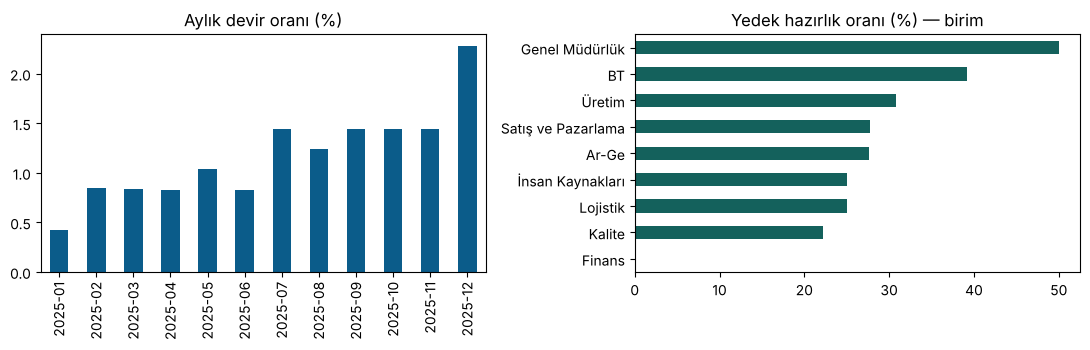

In [24]:
ozet_tablo.to_csv(KOK / "ozet_metrikler.csv", index=False, encoding="utf-8-sig")  # Excel'de Türkçe karakter için BOM
print("Kaydedildi: ozet_metrikler.csv")

# İsteğe bağlı grafik
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    aylik.plot(x="ay", y="devir_%", kind="bar", ax=ax[0], legend=False, color="#0b5c8a")
    ax[0].set_title("Aylık devir oranı (%)"); ax[0].set_xlabel("")
    bb["hazirlik_%"].sort_values().plot(kind="barh", ax=ax[1], color="#14615c")
    ax[1].set_title("Yedek hazırlık oranı (%) — birim"); ax[1].set_ylabel("")
    plt.tight_layout(); plt.show()
except ImportError:
    print("matplotlib kurulu değil; grafik atlandı (pip install matplotlib).")

## C.14 Kendi verinizle kullanım

### 1) Sütun eşleme

Kendi İK sisteminizin dışa aktarımı büyük olasılıkla farklı sütun adları kullanır. Aşağıdaki sözlük, **sizin sütunlarınızı bu defterin beklediği adlara** çevirir; geri kalan kodu değiştirmeniz gerekmez.

In [25]:
# SOL: sizin dosyanızdaki ad   SAĞ: bu defterin beklediği ad
SUTUN_ESLEME = {
    "Personel No":        "sicil_no",
    "Departman":          "birim",
    "Kadro Grubu":        "unvan_grubu",
    "Cinsiyet":           "cinsiyet",
    "Çalışma Şekli":      "istihdam_turu",
    "Haftalık Saat":      "haftalik_saat",
    "İşe Giriş Tarihi":   "ise_baslama_tarihi",
    "İşten Çıkış Tarihi": "ayrilma_tarihi",
    "Çıkış Nedeni":       "ayrilma_turu",
}
DEGER_ESLEME = {            # kod listelerini defterin değerlerine çevirin
    "istihdam_turu": {"Full Time": "Tam zamanlı", "Part Time": "Yarı zamanlı", "Temp": "Geçici"},
    "ayrilma_turu":  {"İstifa": "Gönüllü", "İşveren Feshi": "Gönülsüz", "Emeklilik": "Gönüllü"},
}

def calisan_tablosunu_hazirla(yol, sep=";", encoding="utf-8-sig"):
    """Kendi dışa aktarımınızı okur ve bu defterin beklediği yapıya getirir."""
    t = pd.read_csv(yol, sep=sep, encoding=encoding, dayfirst=True)
    t = t.rename(columns=SUTUN_ESLEME)
    for s, harita in DEGER_ESLEME.items():
        if s in t:
            t[s] = t[s].replace(harita)
    for s in ["ise_baslama_tarihi", "ayrilma_tarihi"]:
        t[s] = pd.to_datetime(t[s], dayfirst=True, errors="coerce")
    eksik = {"sicil_no", "birim", "ise_baslama_tarihi"} - set(t.columns)
    assert not eksik, f"Zorunlu sütun eksik: {eksik}"
    return t.drop_duplicates("sicil_no")

# Kullanım:
#   cal = calisan_tablosunu_hazirla("benim_dosyam.csv")
#   ... C.2'deki kalite kontrollerini yeniden çalıştırın, sonra C.4'ten itibaren devam edin.

### 2) Hangi modülde hangi metrik var?

Her modülün `METRIK_LISTESI` değişkeni, `hesapla()` işlevinin kabul ettiği kimlikleri verir. Bir kimliğin hangi girdileri istediğini görmek için ilgili rehber sayfasındaki hesaplayıcı alanlarına ya da fonksiyonun yardım metnine bakın.

In [26]:
import glob, os
print(f"{'Modül':<28}{'Metrik sayısı':>14}   İlk üç metrik")
for yol in sorted(glob.glob(str(KOK / "modules" / "*.py"))):
    ad = os.path.basename(yol)[:-3]
    m = modul(ad)
    print(f"{ad:<28}{len(m.METRIK_LISTESI):>14}   {', '.join(map(str, m.METRIK_LISTESI[:3]))}")

# Bir fonksiyonun girdilerini görmek:
help(iso30421.aylik_devir)

Modül                        Metrik sayısı   İlk üç metrik
iso23326_metrikler                       9   uwes, katilim, olumlu
iso24178_metrikler                       7   kultur_endeksi, madde_puani, boyut
iso24179_metrikler                      11   kayip_zaman, kayip_zaman_dagilim, kaza_orani
iso30405_isealim                        13   aday_vakans, havuz_gecis, nitelikli_basvuru
iso30406_metrikler                       5   acik, oncelik, kume
iso30407_metrikler                       7   cphi, cphc, hcr
iso30408_metrikler                       8   sapma, aralik, uyum
iso30409_metrikler                      10   arz_acigi, bos_kadro, hareketlilik
iso30410_metrikler                       5   etki_pozisyon, etki_birey, pay
iso30411_metrikler                       5   performans, ksa, grup
iso30414_metrikler                      55   toplam_calisan, fte, tfte
iso30415_metrikler                      11   katilim, olumlu, temsil
iso30421_metrikler                      15   aylik_devir, yil

In [27]:
# Hata yakalama: eksik girdi KeyError, mantıksız girdi ValueError verir
try:
    iso30421.hesapla("aylik_devir", ayrilan=3, ay_basi=0, ay_sonu=0)
except (KeyError, ValueError, ZeroDivisionError) as e:
    print("Hesaplama reddedildi:", type(e).__name__, "-", e)

Hesaplama reddedildi: ZeroDivisionError - float division by zero


### 3) Kontrol listesi: kendi verinizle çalışmadan önce

- [ ] **Gizlilik:** Kişisel veriyi (ad, TCKN, iletişim) dosyadan çıkarın; sicil numarasını yerine takma kod kullanın. Veri işleme izninizi (KVKK) doğrulayın.
- [ ] **Tanım:** “Çalışan”ın kimleri kapsadığını yazın (stajyer, geçici, yüklenici?). FTE ve headcount ayrımını netleştirin.
- [ ] **Dönem:** Rapor dönemini, ay başı/sonu tanımını ve tarih biçimini (GG.AA.YYYY mi?) sabitleyin.
- [ ] **Kalite:** C.2 kontrollerini kendi verinize uygulayın; sorunlu kayıtları düzeltmeden analiz etmeyin ve düzeltmeleri kayıt altına alın.
- [ ] **Küçük gruplar:** Beş-on kişiden küçük gruplarda oran raporlamayın ya da birleştirin (anonimlik).
- [ ] **Çapraz kontrol:** İlk sonuçları eldeki bir bordro ya da yönetim raporuyla karşılaştırın.
- [ ] **Belgeleyin:** Hangi tanımı, hangi formülü ve hangi modül sürümünü kullandığınızı rapora yazın (Ek A.4: aynı adı taşıyan metrikler).
- [ ] **Yorum:** Eşik değerleri kendi geçmişinize ve sektörünüze göre kalibre edin; ISO standartları hedef vermez.

### 4) Sık karşılaşılan hatalar

| Belirti | Olası neden | Çözüm |
|---|---|---|
| `KeyError: 'ay_basi'` | Gerekli girdi verilmedi | İlgili metriğin girdi adlarını rehber sayfasından kontrol edin |
| Devir oranı %100'ü aşıyor | Ay başı mevcut yanlış hesaplandı | `mevcut()` işlevinde tarih sınırını (>, >=) kontrol edin |
| FTE tam zamanlı sayısından küçük | Haftalık saat birimi karışık (aylık / günlük) | Tüm saatleri haftalığa çevirin |
| Tarihler `NaT` çıkıyor | Gün-ay sırası ters (03.04.2025) | `dayfirst=True` kullanın |
| Sonuç Excel'de bozuk karakter | UTF-8 BOM yok | `encoding="utf-8-sig"` ile kaydedin |
| Pyodide'de çalışan kod burada çalışmıyor | Farklı Python sürümü | Modüller yalnızca standart kütüphane kullanır; Python 3.9+ yeterlidir |

---
*Bu defter ve içindeki veriler öğretim amaçlıdır; ISO/TS standartlarının resmî metni yerine geçmez.*